# A3 — Classificador com CNN pré-treinada (transfer learning por feature extraction)

**Disciplina:** Visão Computacional com CNNs e Transformers — Projeto da Disciplina
**Autor:** Raphael Alves Carneiro

| Item | Valor |
|---|---|
| Ambiente | Google Colab, GPU T4 (Runtime → Change runtime type → T4 GPU) |
| Memória de GPU | ~3 GB (ResNet-50 congelada, batch 32, AMP) |
| RAM | ~3 GB |
| Tempo estimado | ~10 a 15 min (download ~1 min, treino baseline ~4 min, experimento opcional com augmentation ~5 min) |
| Dados | Kaggle `pavansanagapati/images-dataset` (~1.800 imagens) |

**Credenciais do Kaggle.** O notebook tenta baixar o dataset via `kagglehub` sem autenticação (funciona para datasets públicos). Se o Kaggle exigir login, basta deixar o arquivo `kaggle.json` em `MyDrive/kaggle.json`: o notebook monta o Drive e lê a credencial sozinho. Nenhuma outra alteração é necessária.

**Roteiro**
1. Configuração do ambiente
2. Download e inspeção do dataset
3. Escolha do modelo pré-treinado (justificativa)
4. 3.1 — Feature extraction: backbone congelado + novo classification head
5. Resultados: curvas, accuracy global e por classe, matriz de confusão, erros
6. 3.2 — Análise e propostas de melhoria (+ experimento opcional com augmentation)
7. Feature extraction vs. fine-tuning

## 1. Configuração do ambiente

In [1]:
!pip -q install kagglehub

import os, json, time, random, hashlib, glob
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
seed_everything()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "sem GPU")

Device: cuda | Tesla T4


In [2]:
# Pasta de saída (figuras e métricas usadas no relatório). Se o Drive estiver montado, salva lá.
SAVE_TO_DRIVE = True
OUT_DIR = Path("/content/outputs/A3")
if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_DIR = Path("/content/drive/MyDrive/PD_VisaoComputacional/A3")
    except Exception as e:
        print("Drive não montado, salvando localmente:", e)
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Saídas em:", OUT_DIR)

Mounted at /content/drive
Saídas em: /content/drive/MyDrive/PD_VisaoComputacional/A3


## 2. Download e inspeção do dataset

In [3]:
import kagglehub

def download_dataset():
    try:
        return kagglehub.dataset_download("pavansanagapati/images-dataset")
    except Exception as e:
        print("Download anônimo falhou, tentando credencial do Drive:", e)
        cred = Path("/content/drive/MyDrive/kaggle.json")
        if not cred.exists():
            raise FileNotFoundError("Coloque o kaggle.json em MyDrive/kaggle.json e rode de novo.")
        k = json.loads(cred.read_text())
        os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = k["username"], k["key"]
        return kagglehub.dataset_download("pavansanagapati/images-dataset")

DATA_ROOT = Path(download_dataset())
print("Dataset em:", DATA_ROOT)
!find "$DATA_ROOT" -maxdepth 3 -type d | head -40

Using Colab cache for faster access to the 'images-dataset' dataset.
Dataset em: /kaggle/input/images-dataset
/kaggle/input/images-dataset
/kaggle/input/images-dataset/data
/kaggle/input/images-dataset/data/horses
/kaggle/input/images-dataset/data/cars
/kaggle/input/images-dataset/data/dogs
/kaggle/input/images-dataset/data/flowers
/kaggle/input/images-dataset/data/data
/kaggle/input/images-dataset/data/data/horses
/kaggle/input/images-dataset/data/data/cars
/kaggle/input/images-dataset/data/data/dogs
/kaggle/input/images-dataset/data/data/flowers
/kaggle/input/images-dataset/data/data/bike
/kaggle/input/images-dataset/data/data/cats
/kaggle/input/images-dataset/data/data/human
/kaggle/input/images-dataset/data/bike
/kaggle/input/images-dataset/data/cats
/kaggle/input/images-dataset/data/human


In [4]:
# Varre todas as imagens e usa a pasta-pai como rótulo.
# Remove duplicatas exatas (por hash) caso o dataset traga cópias em pastas diferentes.
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".gif"}
GENERIC = {"train", "test", "val", "valid", "validation", "data", "images", "dataset"}

rows, seen, corrupted, dup = [], set(), 0, 0
for p in sorted(DATA_ROOT.rglob("*")):
    if p.suffix.lower() not in IMG_EXT:
        continue
    label = p.parent.name
    if label.lower() in GENERIC:
        continue
    h = hashlib.md5(p.read_bytes()).hexdigest()
    if h in seen:
        dup += 1; continue
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception:
        corrupted += 1; continue
    seen.add(h)
    rows.append({"path": str(p), "label": label})

df = pd.DataFrame(rows)
CLASSES = sorted(df.label.unique())
NUM_CLASSES = len(CLASSES)
cls2idx = {c: i for i, c in enumerate(CLASSES)}
df["y"] = df.label.map(cls2idx)
print(f"{len(df)} imagens válidas | {NUM_CLASSES} classes | {dup} duplicatas removidas | {corrupted} corrompidas")
assert NUM_CLASSES >= 2, "Não encontrei pastas de classe; confira a árvore impressa acima."
counts = df.label.value_counts().sort_index()
print(counts)

1764 imagens válidas | 7 classes | 1842 duplicatas removidas | 0 corrompidas
label
bike       364
cars       420
cats       202
dogs       202
flowers    210
horses     183
human      183
Name: count, dtype: int64


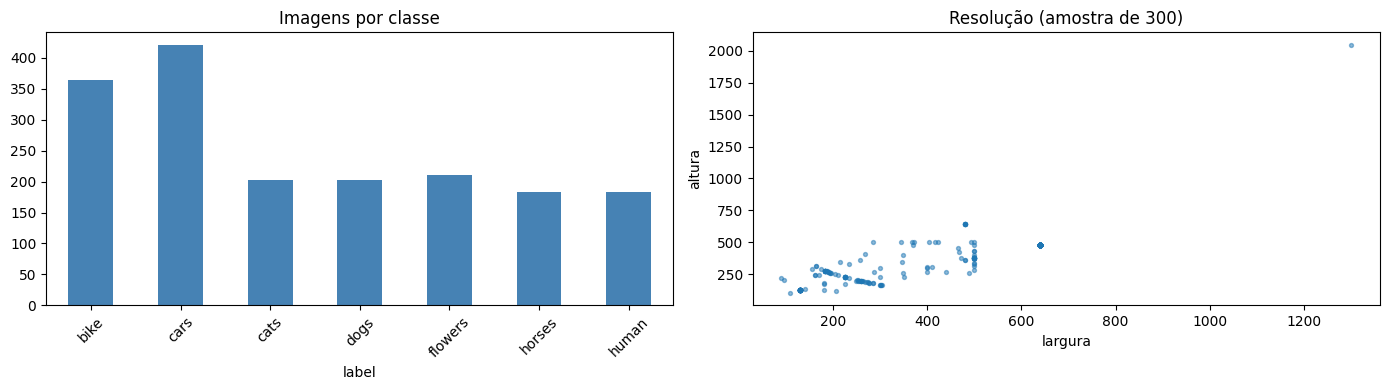

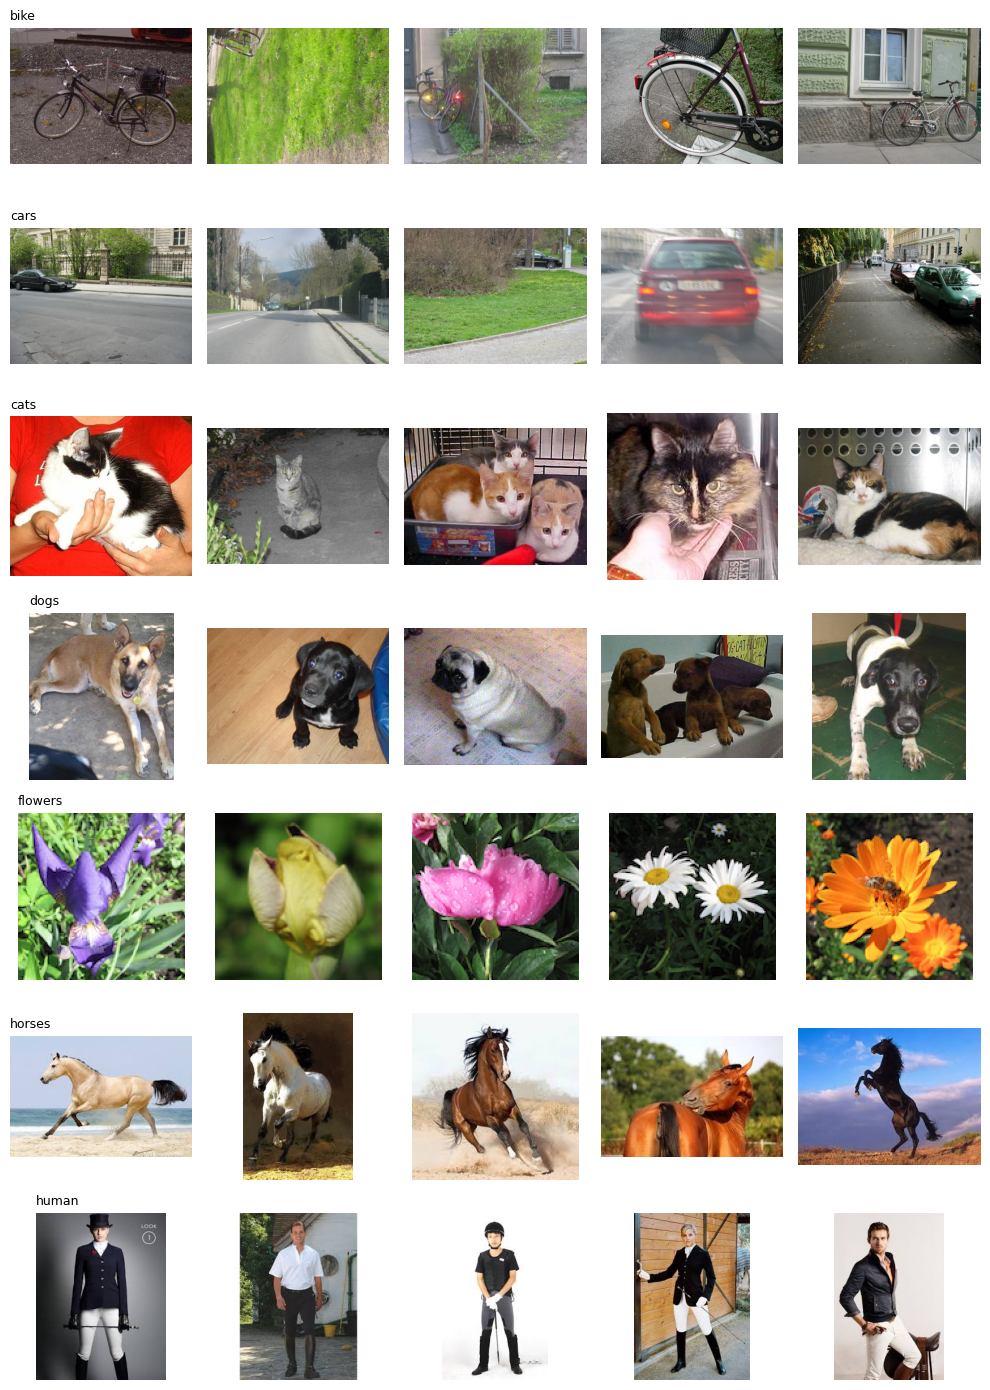

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
counts.plot.bar(ax=ax[0], color="steelblue"); ax[0].set_title("Imagens por classe"); ax[0].tick_params(axis="x", rotation=45)

sizes = [Image.open(p).size for p in df.sample(min(300, len(df)), random_state=SEED).path]
w, h = zip(*sizes)
ax[1].scatter(w, h, s=8, alpha=.5); ax[1].set_xlabel("largura"); ax[1].set_ylabel("altura"); ax[1].set_title("Resolução (amostra de 300)")
plt.tight_layout(); plt.savefig(OUT_DIR / "a3_eda.png", dpi=150); plt.show()

# Grade de exemplos: 5 por classe
n = 5
fig, axes = plt.subplots(NUM_CLASSES, n, figsize=(n * 2, NUM_CLASSES * 2))
axes = np.atleast_2d(axes)
for i, c in enumerate(CLASSES):
    for j, p in enumerate(df[df.label == c].sample(n, random_state=SEED).path):
        axes[i, j].imshow(Image.open(p).convert("RGB")); axes[i, j].axis("off")
    axes[i, 0].set_title(c, loc="left", fontsize=9)
plt.tight_layout(); plt.savefig(OUT_DIR / "a3_amostras.png", dpi=120); plt.show()

In [6]:
# Split estratificado 70/15/15: mantém a proporção de cada classe nos três conjuntos.
train_df, tmp_df = train_test_split(df, test_size=0.30, stratify=df.y, random_state=SEED)
val_df, test_df = train_test_split(tmp_df, test_size=0.50, stratify=tmp_df.y, random_state=SEED)
print(f"treino={len(train_df)} | validação={len(val_df)} | teste={len(test_df)}")

treino=1234 | validação=265 | teste=265


**Duplicatas.** O dataset do Kaggle traz as mesmas imagens duas vezes, em `data/<classe>` e em `data/data/<classe>`. A deduplicação por hash removeu 1.842 cópias e sobraram 1.764 imagens únicas em 7 classes, coerente com as ~1.800 do enunciado. Sem essa etapa, a mesma foto poderia cair no treino e no teste, e a accuracy de teste sairia inflada por vazamento.

O desbalanceamento é moderado: `cars` (420) e `bike` (364) têm cerca do dobro das demais (~180 a 210). O split estratificado mantém essa proporção nos três conjuntos, e reporto macro-F1 além da accuracy para que as classes menores pesem igual.

## 3. Escolha do modelo pré-treinado

Escolhi a **ResNet-50** com os pesos `IMAGENET1K_V2` do torchvision, e não a EfficientNet-B0, por quatro motivos:

1. **Domínio.** O dataset é de objetos comuns fotografados, muito próximo do ImageNet. Nesse cenário as features da última camada convolucional já separam bem as categorias, e é exatamente isso que a feature extraction explora.
2. **Qualidade do vetor de features.** A ResNet-50 entrega um vetor de 2.048 dimensões depois do global average pooling, contra 1.280 da EfficientNet-B0. Com o backbone congelado, só uma camada linear aprende, então quanto mais linearmente separável for esse vetor, melhor.
3. **Colab T4.** São ~25,6 M de parâmetros e ~4,1 GFLOPs por imagem em 224×224. Com o backbone congelado não há gradiente nem estado do otimizador para essas camadas, então o consumo de memória fica em torno de 3 GB. Sobra folga.
4. **Número de classes.** A saída é uma `Linear(2048, NUM_CLASSES)`. Com poucas classes e ~1.800 imagens, o head tem poucos parâmetros para treinar, o que reduz o risco de overfitting.

A EfficientNet-B0 seria a escolha se o limite fosse latência ou memória (5,3 M de parâmetros, ~0,4 GFLOPs). Aqui o gargalo não é esse.

In [7]:
WEIGHTS = models.ResNet50_Weights.IMAGENET1K_V2
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# Pré-processamento idêntico ao do pré-treinamento: resize 232 -> center crop 224 -> normalização ImageNet.
eval_tf = transforms.Compose([
    transforms.Resize(232),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class ImgDataset(Dataset):
    def __init__(self, frame, tf):
        self.paths, self.ys, self.tf = frame.path.tolist(), frame.y.tolist(), tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.tf(img), self.ys[i]

def make_loaders(train_tf, bs=32):
    g = torch.Generator().manual_seed(SEED)
    kw = dict(batch_size=bs, num_workers=2, pin_memory=True)
    return (DataLoader(ImgDataset(train_df, train_tf), shuffle=True, generator=g, **kw),
            DataLoader(ImgDataset(val_df, eval_tf), shuffle=False, **kw),
            DataLoader(ImgDataset(test_df, eval_tf), shuffle=False, **kw))

## 4. Atividade 3.1 — Feature extraction com backbone congelado

In [8]:
def build_feature_extractor(num_classes):
    model = models.resnet50(weights=WEIGHTS)
    for p in model.parameters():          # congela TODO o backbone
        p.requires_grad = False
    in_feats = model.fc.in_features       # 2048
    model.fc = nn.Linear(in_feats, num_classes)   # novo head: único módulo treinável
    return model.to(DEVICE)

model = build_feature_extractor(NUM_CLASSES)
n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Head original do ImageNet: Linear(2048, 1000)  ->  novo head:", model.fc)
print(f"Parâmetros totais: {n_total:,} | treináveis: {n_train:,} ({100*n_train/n_total:.2f}%)")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 191MB/s]


Head original do ImageNet: Linear(2048, 1000)  ->  novo head: Linear(in_features=2048, out_features=7, bias=True)
Parâmetros totais: 23,522,375 | treináveis: 14,343 (0.06%)


In [9]:
def set_feature_extraction_mode(model):
    # Backbone em eval: com os pesos congelados, as BatchNorms também não podem atualizar
    # as médias móveis; senão o "congelamento" vazaria pelas estatísticas.
    model.eval()
    model.fc.train()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    crit = nn.CrossEntropyLoss()
    loss_sum, ys, ps = 0.0, [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            logits = model(x)
        loss_sum += crit(logits.float(), y).item() * len(y)
        ys.append(y.cpu()); ps.append(logits.argmax(1).cpu())
    ys, ps = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return loss_sum / len(ys), (ys == ps).mean(), ys, ps

def train_head(model, train_loader, val_loader, epochs=15, lr=1e-3, tag="baseline"):
    opt = torch.optim.Adam(model.fc.parameters(), lr=lr)
    crit = nn.CrossEntropyLoss()
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")
    hist, best_loss, best_state, best_ep = [], float("inf"), None, 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        set_feature_extraction_mode(model)
        tl, tc, tn = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
                logits = model(x)
                loss = crit(logits.float(), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(y); tc += (logits.argmax(1) == y).sum().item(); tn += len(y)
        vl, va, _, _ = evaluate(model, val_loader)
        hist.append(dict(epoch=ep, train_loss=tl / tn, train_acc=tc / tn, val_loss=vl, val_acc=va))
        # Seleciono a época pela MENOR loss de validação, e não pela accuracy: com ~265 imagens de validação
        # a accuracy empata em várias épocas (cada erro vale 0,4 p.p.) e o critério por accuracy
        # ficaria preso à época 1, com o head ainda mal calibrado.
        if vl < best_loss:
            best_loss, best_ep = vl, ep
            best_state = {k: v.detach().clone() for k, v in model.fc.state_dict().items()}
        print(f"[{tag}] ep {ep:02d} | train loss {tl/tn:.4f} acc {tc/tn:.4f} | val loss {vl:.4f} acc {va:.4f}")
    model.fc.load_state_dict(best_state)   # mantém o head da melhor época em validação
    print(f"Tempo de treino: {time.time()-t0:.1f}s | melhor época: {best_ep} (val loss {best_loss:.4f})")
    return pd.DataFrame(hist)

In [10]:
EPOCHS, LR, BS = 15, 1e-3, 32
seed_everything()
train_loader, val_loader, test_loader = make_loaders(eval_tf, BS)   # baseline: sem augmentation
hist_base = train_head(model, train_loader, val_loader, epochs=EPOCHS, lr=LR, tag="baseline")
hist_base.to_csv(OUT_DIR / "a3_hist_baseline.csv", index=False)

[baseline] ep 01 | train loss 0.8513 acc 0.8898 | val loss 0.2832 acc 0.9925
[baseline] ep 02 | train loss 0.1814 acc 0.9943 | val loss 0.1331 acc 0.9925
[baseline] ep 03 | train loss 0.0966 acc 0.9968 | val loss 0.0898 acc 0.9925
[baseline] ep 04 | train loss 0.0656 acc 0.9976 | val loss 0.0688 acc 0.9925
[baseline] ep 05 | train loss 0.0480 acc 0.9984 | val loss 0.0565 acc 0.9925
[baseline] ep 06 | train loss 0.0376 acc 0.9984 | val loss 0.0478 acc 0.9925
[baseline] ep 07 | train loss 0.0304 acc 0.9992 | val loss 0.0418 acc 0.9925
[baseline] ep 08 | train loss 0.0252 acc 0.9992 | val loss 0.0374 acc 0.9925
[baseline] ep 09 | train loss 0.0212 acc 0.9992 | val loss 0.0339 acc 0.9925
[baseline] ep 10 | train loss 0.0181 acc 0.9992 | val loss 0.0313 acc 0.9925
[baseline] ep 11 | train loss 0.0157 acc 0.9992 | val loss 0.0290 acc 0.9925
[baseline] ep 12 | train loss 0.0138 acc 1.0000 | val loss 0.0273 acc 0.9925
[baseline] ep 13 | train loss 0.0122 acc 1.0000 | val loss 0.0255 acc 0.9925

## 5. Resultados

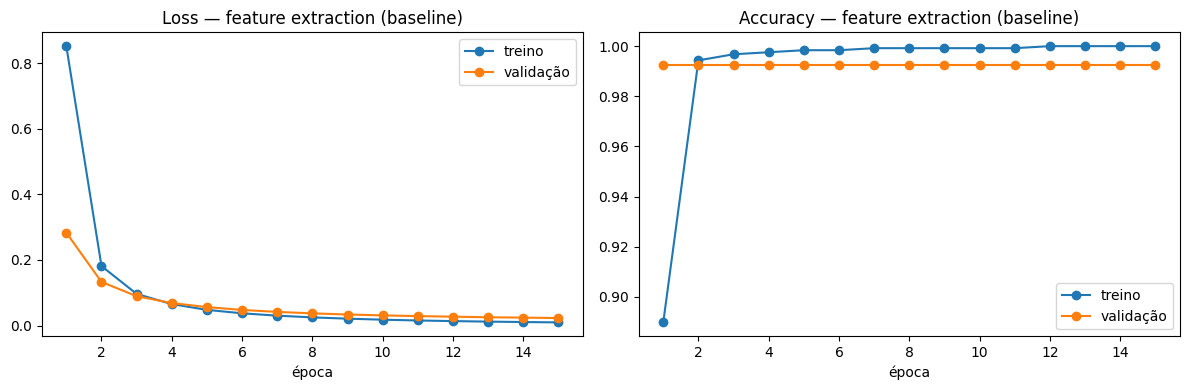

In [11]:
def plot_curves(hist, title, fname):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist.epoch, hist.train_loss, "o-", label="treino"); ax[0].plot(hist.epoch, hist.val_loss, "o-", label="validação")
    ax[0].set_title(f"Loss — {title}"); ax[0].set_xlabel("época"); ax[0].legend()
    ax[1].plot(hist.epoch, hist.train_acc, "o-", label="treino"); ax[1].plot(hist.epoch, hist.val_acc, "o-", label="validação")
    ax[1].set_title(f"Accuracy — {title}"); ax[1].set_xlabel("época"); ax[1].legend()
    plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=150); plt.show()

plot_curves(hist_base, "feature extraction (baseline)", "a3_curvas_baseline.png")

In [12]:
def full_report(model, loader, tag):
    loss, acc, ys, ps = evaluate(model, loader)
    cm = confusion_matrix(ys, ps, labels=range(NUM_CLASSES))
    per_class = cm.diagonal() / cm.sum(1)
    macro_f1 = f1_score(ys, ps, average="macro")
    print(f"[{tag}] TESTE — accuracy global: {acc:.4f} | macro-F1: {macro_f1:.4f} | loss: {loss:.4f}\n")
    print(classification_report(ys, ps, target_names=CLASSES, digits=3, zero_division=0))
    table = pd.DataFrame({"classe": CLASSES, "n_teste": cm.sum(1), "acertos": cm.diagonal(),
                          "accuracy_classe": per_class.round(4)})
    return dict(acc=acc, macro_f1=macro_f1, cm=cm, table=table, ys=ys, ps=ps)

res_base = full_report(model, test_loader, "baseline")
display(res_base["table"])
res_base["table"].to_csv(OUT_DIR / "a3_acc_por_classe_baseline.csv", index=False)

[baseline] TESTE — accuracy global: 1.0000 | macro-F1: 1.0000 | loss: 0.0174

              precision    recall  f1-score   support

        bike      1.000     1.000     1.000        54
        cars      1.000     1.000     1.000        63
        cats      1.000     1.000     1.000        30
        dogs      1.000     1.000     1.000        31
     flowers      1.000     1.000     1.000        32
      horses      1.000     1.000     1.000        28
       human      1.000     1.000     1.000        27

    accuracy                          1.000       265
   macro avg      1.000     1.000     1.000       265
weighted avg      1.000     1.000     1.000       265



,classe,n_teste,acertos,accuracy_classe
0,bike,54,54,1.0
1,cars,63,63,1.0
2,cats,30,30,1.0
3,dogs,31,31,1.0
4,flowers,32,32,1.0
5,horses,28,28,1.0
6,human,27,27,1.0


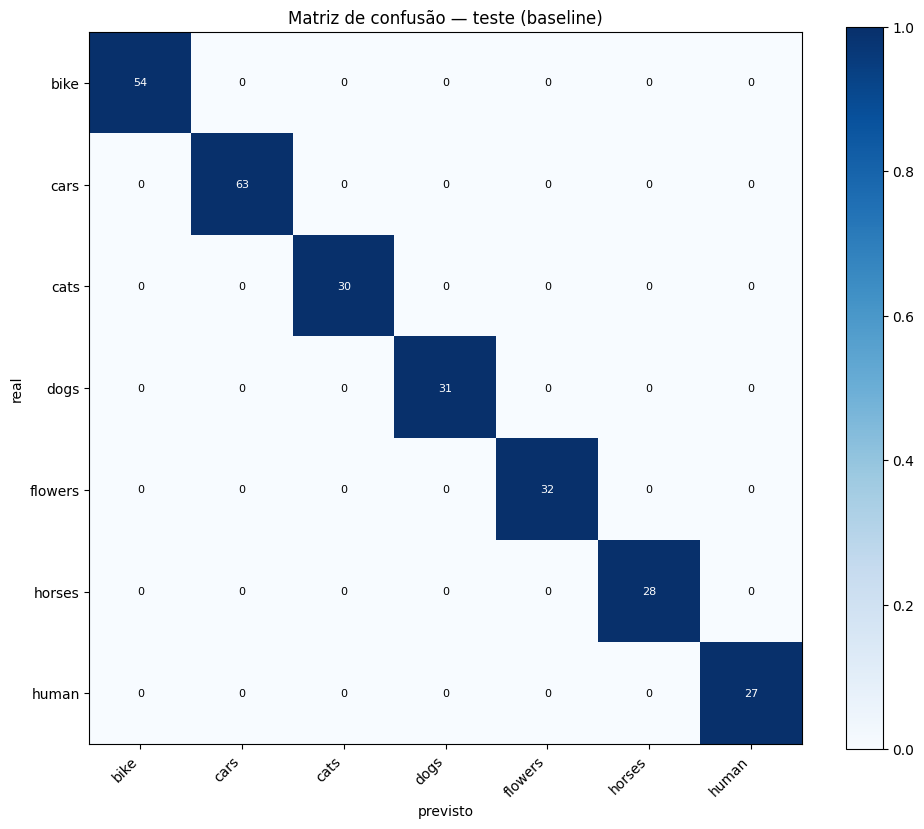

Confusões mais frequentes (real -> previsto):


In [13]:
def plot_cm(cm, title, fname):
    cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(1.0 * NUM_CLASSES + 3, 0.9 * NUM_CLASSES + 2))
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASSES, rotation=45, ha="right")
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASSES)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cmn[i, j] > .5 else "black", fontsize=8)
    ax.set_xlabel("previsto"); ax.set_ylabel("real"); ax.set_title(title); fig.colorbar(im)
    plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=150); plt.show()

plot_cm(res_base["cm"], "Matriz de confusão — teste (baseline)", "a3_cm_baseline.png")

# Pares de classes mais confundidos
cm = res_base["cm"].copy(); np.fill_diagonal(cm, 0)
pairs = sorted(((cm[i, j], CLASSES[i], CLASSES[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if cm[i, j] > 0), reverse=True)[:8]
print("Confusões mais frequentes (real -> previsto):")
for n_, a, b in pairs: print(f"  {a} -> {b}: {n_}")

In [14]:
# Exemplos de erros no teste, para a análise qualitativa
wrong = np.where(res_base["ys"] != res_base["ps"])[0]
print(f"{len(wrong)} erros em {len(res_base['ys'])} imagens de teste")
k = min(12, len(wrong))
if k:
    fig, axes = plt.subplots(2, (k + 1) // 2, figsize=(3 * ((k + 1) // 2), 6.5))
    for ax, i in zip(np.ravel(axes), wrong[:k]):
        ax.imshow(Image.open(test_df.path.iloc[i]).convert("RGB")); ax.axis("off")
        ax.set_title(f"real: {CLASSES[res_base['ys'][i]]}\nprev: {CLASSES[res_base['ps'][i]]}", fontsize=8)
    for ax in np.ravel(axes)[k:]: ax.axis("off")
    plt.tight_layout(); plt.savefig(OUT_DIR / "a3_erros.png", dpi=120); plt.show()

0 erros em 265 imagens de teste



### Leitura dos resultados do baseline

**Accuracy global no teste: 100% (265/265), macro-F1 = 1,000, loss de teste = 0,0174.** Todas as 7 classes acertaram todas as imagens. O treino do head levou 111 s na T4.

**Curvas.** A loss de validação caiu de forma contínua (0,283 → 0,023) sem nunca subir, e a de treino acompanhou de perto. Não há overfitting, o que era esperado: só 14.343 parâmetros treináveis (0,06% do modelo) não conseguem decorar 1.234 imagens.

A accuracy de validação ficou parada em 99,25% (2 erros em 265) da época 1 à 15. Isso mostra que o head já separava as classes depois de uma única época. As épocas seguintes não mudaram quais imagens eram acertadas, só aumentaram a confiança das previsões, e é isso que a queda da loss mede. Foi por isso que passei a escolher a época pela menor loss de validação: na primeira execução, escolhendo pela accuracy, o empate fez o notebook guardar o head da época 1, ainda mal calibrado (loss de teste de 0,29 contra 0,017 agora).

**Como ler o 100%.** Não significa que o modelo nunca erra. Com 265 imagens de teste e zero erros, a regra do três dá um limite superior de ~1,1% para a taxa de erro real, com 95% de confiança (3/265). A validação, com 2 erros, confirma que o modelo não é perfeito. O dataset é fácil para um backbone do ImageNet: as 7 classes (bicicleta, carro, gato, cachorro, flor, cavalo, pessoa) são categorias que o ImageNet já cobre ou das quais tem vizinhas próximas, e as features de 2.048 dimensões as separam linearmente.

**Erros observados.** Na primeira execução, com o head da época 1, os 2 erros de teste foram bicicletas pequenas dentro de cenas de rua (uma ao lado de contêineres de lixo, outra encostada numa parede com gramado), previstas como `cars`. Com o head final esses erros sumiram do teste, mas o caso mostra de onde vem o risco residual: objeto pequeno, com contexto de rua dominando a imagem.


## 6. Atividade 3.2 — Análise e propostas de melhoria

A pergunta que guiou cada proposta foi: *essa transformação produz uma imagem que ainda pertence à mesma classe, e ela simula uma variação que de fato aparece nos dados de teste?* Se a resposta for não, a augmentation vira ruído de rótulo.

**1. Normalização com média e desvio do pré-treinamento (ImageNet).**
Já está aplicada no baseline e não é opcional com backbone congelado. Os filtros da primeira camada da ResNet-50 foram aprendidos esperando entradas com `mean=[0.485, 0.456, 0.406]` e `std=[0.229, 0.224, 0.225]`. Se eu normalizasse com as estatísticas do meu dataset, deslocaria a distribuição das ativações em todas as camadas seguintes e, como nada no backbone pode se readaptar, a qualidade das features cairia. Não vejo classe prejudicada aqui.

**2. Geometric augmentation (flip horizontal, rotação leve, recorte aleatório).**
- *Flip horizontal:* seguro para as 7 classes. Nenhuma delas tem lateralidade semântica: um carro, cavalo ou pessoa espelhado continua sendo da mesma classe, e não há texto nas imagens que ficaria invertido.
- *Rotação leve (±10°):* simula câmera levemente torta. `human`, `horses`, `cars` e `bike` têm orientação canônica (em pé, sobre o chão), então rotações grandes criariam imagens que não aparecem no teste. `flowers`, `cats` e `dogs`, muitas vezes em close, toleram mais.
- *Recorte aleatório (RandomResizedCrop, escala 0,7–1,0):* é o que exige mais cuidado aqui. Na primeira execução, com o head ainda na época 1, os dois erros de teste foram bicicletas **pequenas dentro de cenas de rua** (uma ao lado de contêineres de lixo, outra encostada numa parede com gramado), previstas como `cars`. O modelo está usando o contexto "rua/calçada" como pista. Um recorte agressivo pode cortar a bicicleta e deixar só a rua, reforçando exatamente esse atalho. Por isso limitei a escala mínima a 0,7.

**3. Color augmentation (color jitter, grayscale aleatório).**
- *Brilho/contraste moderados (0,2):* benéfico para todas as classes; as fotos vêm de fontes e iluminações variadas.
- *Hue e grayscale:* o risco está em `flowers`, a classe em que a cor é a pista mais forte. Mudar a matiz ou tirar a cor apaga essa informação. Para `cars` e `bike` a cor é irrelevante (existe carro de toda cor), e `cats`/`dogs` se distinguem mais por forma e textura. Usei hue baixo (0,02) e deixei o grayscale de fora.

**4. Scale variation (resize aleatório + crop, multi-scale training).**
O scatter da EDA mostra resoluções de ~100 px a ~1.300 px e, mais importante, objetos em escalas muito diferentes: há bicicletas em close e bicicletas minúsculas numa cena. É o caso em que variação de escala mais ajudaria, justamente para `bike`. Como o backbone é congelado e foi treinado a 224×224, faço a variação só pelo RandomResizedCrop e mantenho a saída em 224, para não gerar features fora da distribuição que o head vê no teste.

**Ressalva importante sobre augmentation com backbone congelado.** Como os pesos convolucionais não mudam, a augmentation só age no head: ela diversifica os vetores de 2.048 dimensões que a camada linear vê. O ganho costuma ser menor do que em fine-tuning, porque o backbone não aprende invariâncias novas. Por isso testei o efeito na prática no experimento abaixo, em vez de assumir que ajudaria.

[augmentation] ep 01 | train loss 0.8083 acc 0.8987 | val loss 0.2903 acc 0.9925
[augmentation] ep 02 | train loss 0.1848 acc 0.9919 | val loss 0.1417 acc 0.9925
[augmentation] ep 03 | train loss 0.1017 acc 0.9919 | val loss 0.0956 acc 0.9925
[augmentation] ep 04 | train loss 0.0729 acc 0.9935 | val loss 0.0729 acc 0.9925
[augmentation] ep 05 | train loss 0.0556 acc 0.9976 | val loss 0.0595 acc 0.9925
[augmentation] ep 06 | train loss 0.0469 acc 0.9951 | val loss 0.0497 acc 0.9925
[augmentation] ep 07 | train loss 0.0363 acc 0.9976 | val loss 0.0444 acc 0.9925
[augmentation] ep 08 | train loss 0.0304 acc 0.9984 | val loss 0.0399 acc 0.9925
[augmentation] ep 09 | train loss 0.0250 acc 0.9992 | val loss 0.0354 acc 0.9925
[augmentation] ep 10 | train loss 0.0230 acc 0.9984 | val loss 0.0329 acc 0.9962
[augmentation] ep 11 | train loss 0.0194 acc 1.0000 | val loss 0.0299 acc 0.9925
[augmentation] ep 12 | train loss 0.0191 acc 0.9992 | val loss 0.0283 acc 0.9925
[augmentation] ep 13 | train

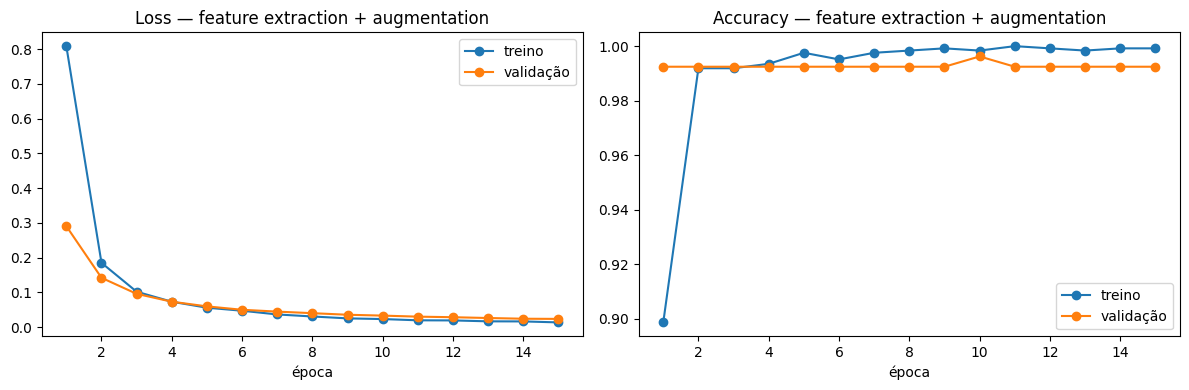

[augmentation] TESTE — accuracy global: 1.0000 | macro-F1: 1.0000 | loss: 0.0182

              precision    recall  f1-score   support

        bike      1.000     1.000     1.000        54
        cars      1.000     1.000     1.000        63
        cats      1.000     1.000     1.000        30
        dogs      1.000     1.000     1.000        31
     flowers      1.000     1.000     1.000        32
      horses      1.000     1.000     1.000        28
       human      1.000     1.000     1.000        27

    accuracy                          1.000       265
   macro avg      1.000     1.000     1.000       265
weighted avg      1.000     1.000     1.000       265



,classe,n_teste,acc_baseline,acc_augmentation,delta
0,bike,54,1.0,1.0,0.0
1,cars,63,1.0,1.0,0.0
2,cats,30,1.0,1.0,0.0
3,dogs,31,1.0,1.0,0.0
4,flowers,32,1.0,1.0,0.0
5,horses,28,1.0,1.0,0.0
6,human,27,1.0,1.0,0.0


In [15]:
RUN_AUG_EXPERIMENT = True   # ~5 min na T4

if RUN_AUG_EXPERIMENT:
    aug_tf = transforms.Compose([
        transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(10),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])
    seed_everything()
    model_aug = build_feature_extractor(NUM_CLASSES)
    tr_aug, _, _ = make_loaders(aug_tf, BS)
    hist_aug = train_head(model_aug, tr_aug, val_loader, epochs=EPOCHS, lr=LR, tag="augmentation")
    hist_aug.to_csv(OUT_DIR / "a3_hist_aug.csv", index=False)
    plot_curves(hist_aug, "feature extraction + augmentation", "a3_curvas_aug.png")
    res_aug = full_report(model_aug, test_loader, "augmentation")

    comp = res_base["table"][["classe", "n_teste", "accuracy_classe"]].rename(columns={"accuracy_classe": "acc_baseline"})
    comp["acc_augmentation"] = res_aug["table"]["accuracy_classe"]
    comp["delta"] = (comp.acc_augmentation - comp.acc_baseline).round(4)
    display(comp)
    comp.to_csv(OUT_DIR / "a3_comparacao_por_classe.csv", index=False)

In [16]:
summary = {"modelo": "ResNet-50 IMAGENET1K_V2 (backbone congelado)", "classes": CLASSES,
           "n_treino": len(train_df), "n_val": len(val_df), "n_teste": len(test_df),
           "epochs": EPOCHS, "lr": LR, "batch": BS,
           "baseline": {"acc": float(res_base["acc"]), "macro_f1": float(res_base["macro_f1"])}}
if RUN_AUG_EXPERIMENT:
    summary["augmentation"] = {"acc": float(res_aug["acc"]), "macro_f1": float(res_aug["macro_f1"])}
    print(pd.DataFrame({k: summary[k] for k in ["baseline", "augmentation"]}).T)
_ = (OUT_DIR / "a3_resumo.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))

              acc  macro_f1
baseline      1.0       1.0
augmentation  1.0       1.0



### Leitura do experimento com augmentation

**Resultado: nenhuma diferença mensurável.** Os dois modelos acertaram 100% do teste. A melhor época foi a 15 nos dois casos, com loss de validação praticamente igual (0,0230 sem augmentation, 0,0235 com) e loss de teste também (0,0174 contra 0,0182). A única diferença concreta foi o custo: o treino com augmentation levou 202 s contra 111 s, porque as transformações são aplicadas imagem a imagem em cada época.

**Por que não ajudou.** Aqui atuam dois efeitos juntos, e o experimento não consegue separá-los:
1. **Teto do dataset.** Com o baseline já em 100% no teste e 99,25% na validação, não sobra erro para a augmentation corrigir. O conjunto de teste é pequeno e fácil demais para medir um ganho.
2. **Backbone congelado.** A augmentation só muda os vetores que chegam ao head linear. Ela não ensina invariâncias novas às camadas convolucionais, que continuam iguais. As features da ResNet-50 já eram razoavelmente invariantes a flip, recorte leve e variação de brilho, porque ela foi treinada no ImageNet com esse mesmo tipo de augmentation.

**O que eu faria para avaliar de verdade.** Em vez de medir no teste original, criaria um teste de robustez: as mesmas 265 imagens com rotação, recorte forte, mudança de cor e redução de escala, comparando baseline e modelo com augmentation. É nesse cenário, com bicicleta pequena na cena e flor com a cor alterada, que as propostas da seção 6 deveriam fazer diferença. No teste limpo, a conclusão honesta é que, para este dataset, feature extraction sem augmentation já basta.


## 7. Feature extraction vs. fine-tuning

A decisão depende de duas variáveis: **quantos dados rotulados eu tenho** e **quão distante meu domínio está do ImageNet**.

| | Domínio parecido com ImageNet | Domínio diferente (raio-X, satélite, microscopia) |
|---|---|---|
| **Poucos dados** (centenas a poucos milhares) | **Feature extraction.** As features já servem e treinar o backbone com pouco dado leva a overfitting. | Feature extraction das camadas intermediárias ou fine-tuning só dos últimos blocos, com lr baixo e muita regularização. |
| **Muitos dados** (dezenas de milhares ou mais) | Fine-tuning completo com lr baixo (ex.: 1e-4 no backbone, 1e-3 no head) dá ganho marginal, mas consistente. | **Fine-tuning completo.** As features de alto nível do ImageNet são pouco relevantes e precisam ser reaprendidas. |

Este dataset tem ~1.800 imagens de objetos do dia a dia, o que o coloca no quadrante superior esquerdo. Feature extraction é a escolha certa como ponto de partida: treina em minutos, tem poucos parâmetros livres (2.048 × nº de classes + bias) e aproveita o fato de o ImageNet já conter praticamente essas categorias.

Se eu fosse além, o próximo passo seria um **fine-tuning parcial**: descongelar só o `layer4` da ResNet-50 com lr de 1e-5 a 1e-4, manter o head com lr de 1e-3, usar as augmentations que se mostraram seguras acima e early stopping pela loss de validação. Descongelar a rede inteira com 1.234 imagens de treino provavelmente pioraria a generalização. Neste dataset específico, porém, o fine-tuning não é necessário: a feature extraction já chegou a 100% no teste.